In [50]:
import matplotlib.pyplot as plt
from f1strategy.data import load_season, FIGURES_DIR
from f1strategy.degradation import pace_delta, training_testing_split, fit, FORMULA, FORMULA_WITHOUT_LAP
from sklearn.metrics import mean_absolute_error, median_absolute_error
import pandas as pd

In [32]:
#load the 2025 season and check the sizes of both
cleaned_data, raw_data = load_season(2025)
print(f"Cleaned data size: {len(cleaned_data)}")
print(f"Raw data size: {len(raw_data)}")

Cleaned data size: 20461
Raw data size: 24058


In [33]:
#Run the pace delta analysis on the cleaned data
cleaned_data_pace_delta = pace_delta(cleaned_data)
print(cleaned_data_pace_delta.head(40))

    Year  RoundNumber           EventName  Location Driver     Team  Stint  \
0   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
1   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
2   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
3   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
4   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
5   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
6   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
7   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
8   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
9   2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    1.0   
10  2025            2  Chinese Grand Prix  Shanghai    PIA  McLaren    2.0   
11  2025            2  Chinese Grand Prix  Shanghai    PIA  McLa

In [34]:
#We want to filter out the laps that have a refrence tyre life greater then 2, since they are old tyres from qualifying or have already degraded from saftey car
filtered_data = cleaned_data_pace_delta[cleaned_data_pace_delta["RefTyreLife"] <= 2]
print(f"Filtered data size: {len(filtered_data)}")
filtered_data.head(40)

Filtered data size: 13644


,Year,RoundNumber,EventName,Location,Driver,Team,Stint,StintId,LapNumber,LapTime_s,TyreLife,Compound,TrackStatus,PitInTime_s,PitOutTime_s,IsAccurate,PaceDelta_s,RefTyreLife
0,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,2.0,97.551,2.0,MEDIUM,1,NaN,NaN,True,0.000,2.0
1,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,4.0,97.804,4.0,MEDIUM,1,NaN,NaN,True,0.253,2.0
2,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,5.0,98.082,5.0,MEDIUM,1,NaN,NaN,True,0.531,2.0
3,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,7.0,97.898,7.0,MEDIUM,1,NaN,NaN,True,0.347,2.0
4,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,8.0,98.193,8.0,MEDIUM,1,NaN,NaN,True,0.642,2.0
5,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,9.0,98.199,9.0,MEDIUM,1,NaN,NaN,True,0.648,2.0
6,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,10.0,97.994,10.0,MEDIUM,1,NaN,NaN,True,0.443,2.0
7,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,11.0,98.124,11.0,MEDIUM,1,NaN,NaN,True,0.573,2.0
8,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,12.0,98.113,12.0,MEDIUM,1,NaN,NaN,True,0.562,2.0
9,2025,2,Chinese Grand Prix,Shanghai,PIA,McLaren,1.0,2025_2_PIA_1,13.0,97.955,13.0,MEDIUM,1,NaN,NaN,True,0.404,2.0


In [35]:
#Group by compound and tyre age so we can plot the median pace delta
grouped_data = filtered_data.groupby(["Compound", "TyreLife"])["PaceDelta_s"].median().reset_index()

grouped_data.rename(columns={"PaceDelta_s": "MedianGroupPaceDelta_s"}, inplace=True)

#Add number of laps for each group so we can drop unsupported groups
grouped_data["NumLapsInGroup"] = filtered_data.groupby(["Compound", "TyreLife"])["PaceDelta_s"].count().values

print(grouped_data.head(20))
print(len(grouped_data))

   Compound  TyreLife  MedianGroupPaceDelta_s  NumLapsInGroup
0      HARD       1.0                  0.0000               6
1      HARD       2.0                  0.0000             250
2      HARD       3.0                 -0.0560             241
3      HARD       4.0                  0.0000             239
4      HARD       5.0                 -0.0310             231
5      HARD       6.0                 -0.0285             224
6      HARD       7.0                 -0.0860             227
7      HARD       8.0                 -0.0760             238
8      HARD       9.0                 -0.1020             235
9      HARD      10.0                 -0.1160             231
10     HARD      11.0                 -0.1040             231
11     HARD      12.0                 -0.1050             228
12     HARD      13.0                 -0.1425             224
13     HARD      14.0                 -0.1025             224
14     HARD      15.0                 -0.2160             225
15     H

In [36]:
#Get rid of groups with insufficient laps since the median is not reliable and not worth plotting
grouped_data = grouped_data[grouped_data["NumLapsInGroup"] >= 30]

print(grouped_data.head(20))
print(len(grouped_data))


   Compound  TyreLife  MedianGroupPaceDelta_s  NumLapsInGroup
1      HARD       2.0                  0.0000             250
2      HARD       3.0                 -0.0560             241
3      HARD       4.0                  0.0000             239
4      HARD       5.0                 -0.0310             231
5      HARD       6.0                 -0.0285             224
6      HARD       7.0                 -0.0860             227
7      HARD       8.0                 -0.0760             238
8      HARD       9.0                 -0.1020             235
9      HARD      10.0                 -0.1160             231
10     HARD      11.0                 -0.1040             231
11     HARD      12.0                 -0.1050             228
12     HARD      13.0                 -0.1425             224
13     HARD      14.0                 -0.1025             224
14     HARD      15.0                 -0.2160             225
15     HARD      16.0                 -0.1480             212
16     H

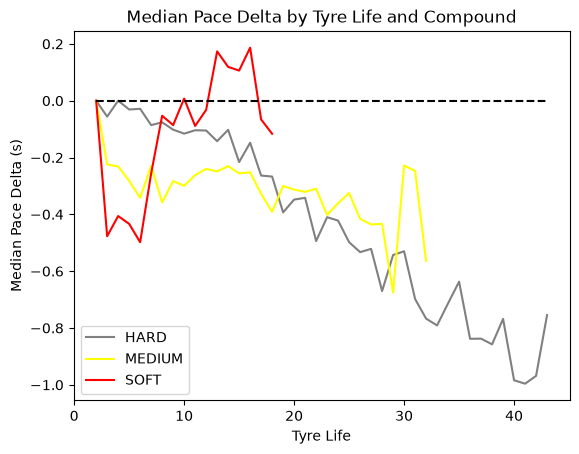

In [87]:
#Plot the median pace delta for each compound and tyre age
colors = {"SOFT": "red", "MEDIUM": "yellow", "HARD": "grey"}

for compound in grouped_data["Compound"].unique():
    compound_data = grouped_data[grouped_data["Compound"] == compound]
    plt.plot(compound_data["TyreLife"], compound_data["MedianGroupPaceDelta_s"], label=compound, color=colors[compound])

#line across 0 for reference
plt.plot([grouped_data["TyreLife"].min(), grouped_data["TyreLife"].max()], [0, 0], 'k--')

plt.title("Median Pace Delta by Tyre Life and Compound")
plt.xlabel("Tyre Life")
plt.ylabel("Median Pace Delta (s)")
plt.legend()

plt.savefig(FIGURES_DIR / "median_pace_delta_by_tyre_life_and_compound.png", bbox_inches='tight', dpi=800)

plt.show()

#### Fuel versus tyre wear

We can see in the above figure the effects of fuel onboard F1 cars. As laps go on, the fuel in the car gets lighter and lighter, meaning the laps get faster and faster. This is clear from the hard and medium tyres getting faster and faster with the life of each tyre. Our model will need to separate the effect of fuel weight from the effect of tyre degradation so we can see these curves rise. Soft tyres begin to rise so quickly because after about 6 laps the soft rubber degrades massively, which is a bigger effect than the fuel.

### Split into Training and Testing Sets with 80/20 split

In [38]:
training_data, testing_data = training_testing_split(cleaned_data, test_size=0.2, random_state=42)

print(len(training_data))
print(len(testing_data))

#make sure no stintID appears in both training and testing sets
assert set(training_data["StintId"]).isdisjoint(set(testing_data["StintId"]))

print(f"Ratio of test set to cleaned data: {len(testing_data) / len(cleaned_data)*100 :.2f}%")
print(f"Ratio of training set to cleaned data: {len(training_data) / len(cleaned_data)*100 :.2f}%")

#make sure every circuit dirver and compound in the testing set also appears in the training set
assert set(testing_data["EventName"]).issubset(set(training_data["EventName"]))
assert set(testing_data["Driver"]).issubset(set(training_data["Driver"]))
assert set(testing_data["Compound"]).issubset(set(training_data["Compound"]))

print("All checks passed successfully.")

16407
4054
Ratio of test set to cleaned data: 19.81%
Ratio of training set to cleaned data: 80.19%
All checks passed successfully.


We will use the same seed in all future calls of this function so that the splits remain frozen and we can fairly evaluate our models.

### Fitting Models

In [39]:
print(FORMULA)

LapTime_s ~ C(Compound) + TyreLife : Compound + I(TyreLife ** 2) : Compound + TyreLife : C(EventName) + LapNumber + C(EventName) + C(Driver)


We are going to fit a regression that predicts lap time in seconds based on a specific design matrix. We build this design matrix from our training data as defined by the features in the above formula. The features are as follows:

- C(Compound): What tyre we are actually on, Soft, Medium, or Hard, which changes how fast the tyre is when it is fresh.
- TyreLife : Compound: How many laps old is this specific tyre and what compound is it? Older tyres will be slower, but an older soft will be much slower than an older hard.
- I(TyreLife ** 2) : Compound: Same as above except we square the TyreLife to capture the curve, which we showed in notebook 1 where lap time rose almost exponentially with tyre age in one stint.
- TyreLife : C(EventName): Different tracks have grittier asphalt and are going to wear down tyres faster. We need to know for each track how much faster or slower tyres wear there. This adjustment is the same for all three compounds.
- LapNumber: Lap number stands in for fuel weight on the car because we do not have this data. As the race goes on the car gets lighter and lap time will get faster. We need to separate this effect from the degradation of the tyres.
- C(EventName): We also want to know the effect of each race in the calendar. Different tracks have vastly different average lap times, and we want to know given a certain circuit how fast we are going to be.
- C(Driver): Same as the effect of each race, but for drivers. A faster driver and car will be quicker every lap, so we need to learn that or it would get blamed on the tyres. This does not capture how well a driver manages their tyres.

In [40]:
model = fit(training_data, FORMULA)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              LapTime_s   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                 3.177e+04
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:40:45   Log-Likelihood:                -20233.
No. Observations:               16407   AIC:                         4.061e+04
Df Residuals:                   16337   BIC:                         4.115e+04
Df Model:                          69                                         
Covariance Type:            nonrobust                                         
                                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------

#### What the model learned

| Check | Expected | Result | Pass |
|---|---|---|---|
| Lap number (fuel) | negative | −0.050 s per lap | Yes |
| Tyre age makes laps slower | positive for all compounds | Hard 0.057, Medium 0.039, Soft 0.034 | Yes |
| Soft has a cliff | soft squared term positive | 0.0006 | Yes |
| Soft is fastest when fresh | soft and medium negative compared to hard | Soft +0.16, Medium +0.20 | No |
| Soft wears fastest early | soft slope largest | hard slope largest | No |

- Fuel and tyre wear are now separated. Every compound gets slower with age once lap number is in the model.
- Circuit wear matches real tracks. Bahrain, Austria, São Paulo and Spain wear tyres the most. Baku, Las Vegas, Qatar, Monza and Suzuka the least.
- Driver order matches 2025. Piastri, Norris and Verstappen fastest, Alpines slowest.
- Compound baselines are backwards, most likely because softs and mediums are used in first stint traffic while hards run later in clean air.

In [41]:
#perdict on the testing data
predictions = model.predict(testing_data)
predictions.head(20)

0     99.363630
1     99.319402
2     99.231835
3     99.188497
4     99.145456
5     99.102712
6     98.889049
7     98.799701
8     98.755473
9     98.667906
10    98.624568
11    98.581527
12    98.538783
13    98.496336
14    98.088872
15    98.059979
16    98.030571
17    98.000650
18    97.970214
19    97.939264
dtype: float64

In [58]:
#MAE Overall
mae_overall = mean_absolute_error(testing_data['LapTime_s'], predictions)

median_ae_overall = median_absolute_error(testing_data['LapTime_s'], predictions)

In [52]:
#Calcualte MAE for each tyre compound

#Add absolute error column
testing_data['AbsoluteError'] = abs(testing_data['LapTime_s'] - predictions)

#Calculate MAE for each tyre compound
mae_by_compound = testing_data.groupby('Compound')['AbsoluteError'].mean()

#Median Absolute Error for each tyre compound
median_ae_by_compound = testing_data.groupby('Compound')['AbsoluteError'].median()

### What does removing LapNumber as a feature do?

In [44]:
#Remove lap number from the training and testing data
model_without_lap = fit(training_data, FORMULA_WITHOUT_LAP)

In [54]:
predictions_without_lap = model_without_lap.predict(testing_data)

mae_without_lap = mean_absolute_error(testing_data["LapTime_s"], predictions_without_lap)
median_ae_without_lap = median_absolute_error(testing_data["LapTime_s"], predictions_without_lap)

In [55]:
#Calcualte MAE for each tyre compound on the testing data without lap information

#Add absolute error column
testing_data['AbsoluteErrorWithoutLap'] = abs(testing_data['LapTime_s'] - predictions_without_lap)

#Calculate MAE for each tyre compound
mae_by_compound_without_lap = testing_data.groupby('Compound')['AbsoluteErrorWithoutLap'].mean()

#Median Absolute Error for each tyre compound
median_ae_by_compound_without_lap = testing_data.groupby('Compound')['AbsoluteErrorWithoutLap'].median()

In [59]:
# Create a comparison table for MAE and Median AE by compound for both models
comparsion_table = pd.DataFrame({
    "MAE Full Model": mae_by_compound,
    "Median AE Full Model": median_ae_by_compound,
    "MAE Without Lap": mae_by_compound_without_lap,
    "Median AE Without Lap": median_ae_by_compound_without_lap
})

#Add a row for overall MAE and Median AE
comparsion_table.loc["Overall"] = [
    mae_overall,
    median_ae_overall,
    mae_without_lap,
    median_ae_without_lap
]

comparsion_table

,MAE Full Model,Median AE Full Model,MAE Without Lap,Median AE Without Lap
Compound,,,,
HARD,0.585047,0.438434,0.842472,0.713926
MEDIUM,0.522945,0.395140,0.884506,0.748254
SOFT,0.649136,0.449732,1.168955,1.084750
Overall,0.565136,0.416901,0.896457,0.766772


We can see that the overall MAE is about 0.565 seconds, which is only about 0.6% of an average 90 second lap. We can also see that the median is lower than the mean for each compound, which shows most laps are predicted closely and the mean is pulled up by a few large misses that are likely caused by traffic or driver mistakes during a race.

In [62]:
#Coefficient comparison of both models
names = [f"TyreLife:Compound[{c}]" for c in ["HARD", "MEDIUM", "SOFT"]]

pd.DataFrame({
    "Full Model": model.params[names],
    "No Fuel Feature Model": model_without_lap.params[names],
})

,Full Model,No Fuel Feature Model
TyreLife:Compound[HARD],0.056843,0.004244
TyreLife:Compound[MEDIUM],0.038886,-0.004862
TyreLife:Compound[SOFT],0.034412,-0.018765


We can clearly see without using LapNumber as a feauture to learn the effects of the fuel weight left in the car, the model learns the completly wrong effect of tyre degredation. Laps start to get faster as tyres age.

### Lap Time Curves by Compound

In [93]:
#Out model as input now takes a driver, a circuit, a lap number, and tyre life for different compounds in order to make a perdiction on lap times
#We want to fix the driver, circuit, and lap number while varying tyre life for different compounds so that we can analyze the impact of tyre degradation on lap times
max_soft_life = 18
max_medium_life = 32
max_hard_life = 43

fixed_driver = "ALB"
fixed_circuit = "Abu Dhabi Grand Prix"
fixed_lap_number = 45

input_table = pd.DataFrame({
    "Driver": [fixed_driver] * (max_soft_life + max_medium_life + max_hard_life),
    "EventName": [fixed_circuit] * (max_soft_life + max_medium_life + max_hard_life),
    "LapNumber": [fixed_lap_number] * (max_soft_life + max_medium_life + max_hard_life),
    "TyreLife": list(range(1, max_soft_life + 1)) + list(range(1, max_medium_life + 1)) + list(range(1, max_hard_life + 1)),
    "Compound": ["SOFT"] * max_soft_life + ["MEDIUM"] * max_medium_life + ["HARD"] * max_hard_life
})

input_table.head(20)

,Driver,EventName,LapNumber,TyreLife,Compound
0,ALB,Abu Dhabi Grand Prix,45,1,SOFT
1,ALB,Abu Dhabi Grand Prix,45,2,SOFT
2,ALB,Abu Dhabi Grand Prix,45,3,SOFT
3,ALB,Abu Dhabi Grand Prix,45,4,SOFT
4,ALB,Abu Dhabi Grand Prix,45,5,SOFT
5,ALB,Abu Dhabi Grand Prix,45,6,SOFT
6,ALB,Abu Dhabi Grand Prix,45,7,SOFT
7,ALB,Abu Dhabi Grand Prix,45,8,SOFT
8,ALB,Abu Dhabi Grand Prix,45,9,SOFT
9,ALB,Abu Dhabi Grand Prix,45,10,SOFT


In [94]:
compound_curve_predictions = model.predict(input_table)

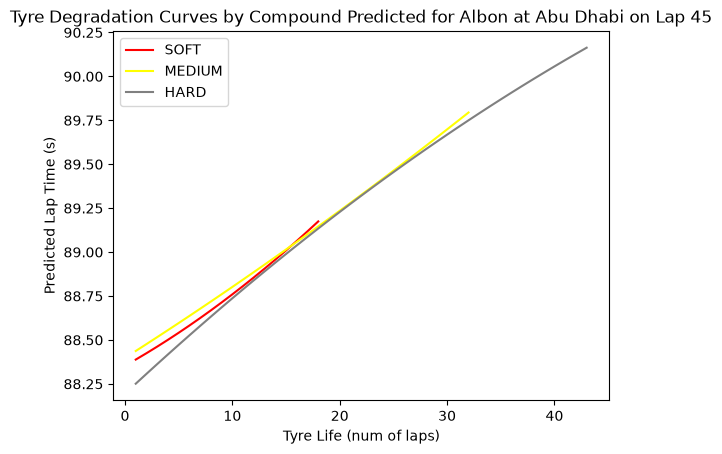

In [95]:
#Plot the degradation curves by compound from our predictions on fixed event, driver, and lap number
colors = {"SOFT": "red", "MEDIUM": "yellow", "HARD": "grey"}

compounds = input_table["Compound"].unique()

for compound in compounds:
    #Get the indexes from the input table for the current compound
    compound_indexes = input_table[input_table["Compound"] == compound].index
    compound_data_y = compound_curve_predictions.loc[compound_indexes]
    tyre_life_x = input_table.loc[compound_indexes, "TyreLife"]
    plt.plot(tyre_life_x, compound_data_y, label=compound, color=colors[compound])

plt.title("Tyre Degradation Curves by Compound Predicted for Albon at Abu Dhabi on Lap 45")
plt.ylabel("Predicted Lap Time (s)")
plt.xlabel("Tyre Life (num of laps)")
plt.legend()

plt.savefig(FIGURES_DIR / "predicted_degradation_by_compound.png", bbox_inches='tight', dpi=800)

plt.show()

We can see now that after seperating the effects down to just the effect of tyre life on perdicted lap time we have a model for degredation. We can see that soft, medium and hard tyres all get slower with age. We can also see that the soft tyre starts to bend upwards at the end of its lifespan which is the cliff where the tyre degrades so much that lap times rise faster and faster. We can also see that hard tyres start out the fastest and then all three tyres converge by about lap 15 of life in the learned model. This suggests that when we perdict optimum stratagey a lot of our strategy will come down to when we stop and how many stops we make rather then which compound of tyre we put on during each stint.